# Data reduction and 3D analysis


In this tutorial, we present the basics steps for a 3D stacked analysis. The main aim is to perform a spectral and morphological analysis of a given source. We are going to analyse the data from the High Energy Stereoscopic System (H.E.S.S.) towards the SNR RX J1713.7-3946. 

Let's start with some basic imports:

In [1]:
from astropy.coordinates import SkyCoord
import astropy.units as u
from regions import CircleSkyRegion
import matplotlib.pyplot as plt
import numpy as np

from gammapy.data import DataStore
from gammapy.datasets import MapDataset, Datasets
from gammapy.estimators import ExcessMapEstimator
from gammapy.maps import MapAxis, WcsGeom, RegionGeom
from gammapy.makers import (
    MapDatasetMaker,
    SafeMaskMaker,
    FoVBackgroundMaker,
)

In [2]:
data_store = DataStore.from_dir(f"$GAMMAPY_DATA/hess-dl3-dr1")

Lets look at the information for that datastore.

In [3]:
data_store.info()

Data store:
HDU index table:
BASE_DIR: /Users/mcarrasco/Prog/gammapy/gammapy-datasets/dev/hess-dl3-dr1
Rows: 630
OBS_ID: 20136 -- 47829
HDU_TYPE: ['aeff', 'bkg', 'edisp', 'events', 'gti', 'psf']
HDU_CLASS: ['aeff_2d', 'bkg_3d', 'edisp_2d', 'events', 'gti', 'psf_table']


Observation table:
Observatory name: 'N/A'
Number of observations: 105



In [ ]:
target_position = SkyCoord.from_name("RX J1713.7-3946").galactic

In [4]:
from gammapy.catalog import SourceCatalogGammaCat

catalog = SourceCatalogGammaCat()
source = catalog["RX J1713.7-3946"]
source

/Users/mcarrasco/Prog/gammapy/gammapy_dev/gammapy/catalog/gammacat.py:125: FutureWarning: Format strings passed to MaskedConstant are ignored, but in future may error or produce different behavior
  ss += f"Significance: {d.significance:.3f}\n"


### What are the galactic coordinates of this source?

In [6]:
target_position = source.position.galactic
target_position

<SkyCoord (Galactic): (l, b) in deg
    (347.26942493, -0.25690467)>

In [7]:
target_position.cartesian

<CartesianRepresentation (x, y, z) [dimensionless]
    (0.97540728, -0.22036454, -0.00448382)>

We can now define an observation filter to select only the relevant observations. Here we use a cone search which we define with a python dict.

We then filter the ObservationTable with `~gammapy.data.ObservationTable.select_observations()`.


In [9]:
selection = dict(
    type="sky_circle",
    frame="galactic",
    lon=target_position.l,
    lat=target_position.b,
    radius="5 deg",
)
selected_obs_table = data_store.obs_table.select_observations(selection)
selected_obs_table

OBS_ID,RA_PNT,DEC_PNT,GLON_PNT,GLAT_PNT,ZEN_PNT,ALT_PNT,AZ_PNT,OBJECT,RA_OBJ,DEC_OBJ,OFFSET_OBJ,ONTIME,LIVETIME,DEADC,TSTART,TSTOP,DATE-OBS,TIME-OBS,DATE-END,TIME-END,N_TELS,TELLIST,QUALITY,MUONEFF,EVENT_COUNT,TARGET_NAME,TARGET_TAG,TARGET_OFFSET,SAFE_ENERGY_LO,SAFE_ENERGY_HI
,deg,deg,deg,deg,deg,deg,deg,,deg,deg,deg,s,s,,s,s,,,,,,,,,,,,deg,TeV,TeV
int64,float32,float32,float32,float32,float32,float32,float32,bytes18,float32,float32,float32,float32,float32,float32,float64,float64,bytes10,bytes12,bytes10,bytes12,int64,bytes7,int64,float32,int64,bytes21,bytes14,float32,float32,float32
20326,259.29852,-39.762222,347.74036,-1.0417831,18.712194,71.2878,154.81943,RXJ 1713.7-3946,258.3879,-39.762222,0.6999909,1683.0,1500.009,0.891271,103858277.0,103859960.0,2004-04-17,01:32:21.184,2004-04-17,02:00:24.184,4,"1,2,3,4",0,1.1412385,16880,RX J1713.7-3946,rxj1713,0.7252947,0.23442288,100.0
20327,257.47733,-39.762222,346.91946,0.092252225,16.734882,73.265114,173.0282,RXJ 1713.7-3946,258.3879,-39.762222,0.69996744,1683.0,1497.074,0.889527,103860109.0,103861792.0,2004-04-17,02:02:53.184,2004-04-17,02:30:56.184,4,"1,2,3,4",0,1.1392112,16995,RX J1713.7-3946,rxj1713,0.6746846,0.20417379,100.0
20349,259.29852,-39.762222,347.74036,-1.0417831,16.722466,73.277534,186.67764,RXJ 1713.7-3946,258.3879,-39.762222,0.6999909,1682.0,1494.5023,0.888527,103947504.0,103949186.0,2004-04-18,02:19:28.184,2004-04-18,02:47:30.184,4,"1,2,3,4",0,1.1592567,16141,RX J1713.7-3946,rxj1713,0.7252947,0.20417379,100.0
20350,257.47733,-39.762222,346.91946,0.092252225,18.658506,71.34149,204.89865,RXJ 1713.7-3946,258.3879,-39.762222,0.69996744,1682.0,1497.6545,0.890401,103949330.0,103951012.0,2004-04-18,02:49:54.184,2004-04-18,03:17:56.184,4,"1,2,3,4",0,1.1565586,16081,RX J1713.7-3946,rxj1713,0.6746846,0.23442288,100.0
20396,258.3879,-39.06222,347.8998,-0.062237248,16.931627,73.068375,190.61954,RXJ 1713.7-3946,258.3879,-39.762222,0.70000076,1683.0,1499.001,0.89067197,104120195.0,104121878.0,2004-04-20,02:17:39.184,2004-04-20,02:45:42.184,4,"1,2,3,4",0,1.1642822,16418,RX J1713.7-3946,rxj1713,0.7092343,0.20417379,100.0
20397,258.3879,-40.462223,346.76566,-0.8830993,19.253716,70.746284,207.88188,RXJ 1713.7-3946,258.3879,-39.762222,0.70000076,1682.0,1505.1713,0.89487,104122008.0,104123690.0,2004-04-20,02:47:52.184,2004-04-20,03:15:54.184,4,"1,2,3,4",0,1.1711123,15798,RX J1713.7-3946,rxj1713,0.691681,0.23442288,100.0
20421,258.3879,-40.462223,346.76566,-0.8830993,16.978054,73.02195,191.29669,RXJ 1713.7-3946,258.3879,-39.762222,0.70000076,1683.0,1501.066,0.891899,104206423.0,104208106.0,2004-04-21,02:14:47.184,2004-04-21,02:42:50.184,4,"1,2,3,4",0,1.1678016,16313,RX J1713.7-3946,rxj1713,0.691681,0.20417379,100.0
20422,258.3879,-39.06222,347.8998,-0.062237248,19.3917,70.6083,208.46205,RXJ 1713.7-3946,258.3879,-39.762222,0.70000076,1683.0,1503.3414,0.893251,104208248.0,104209931.0,2004-04-21,02:45:12.184,2004-04-21,03:13:15.184,4,"1,2,3,4",0,1.1671224,16168,RX J1713.7-3946,rxj1713,0.7092343,0.23442288,100.0


### Look at what is in that selected table


We can now retrieve the relevant observations by passing their obs_id to the `~gammapy.data.DataStore.get_observations()` method.


In [10]:
observations = data_store.get_observations(selected_obs_table["OBS_ID"].data)

### View those observations

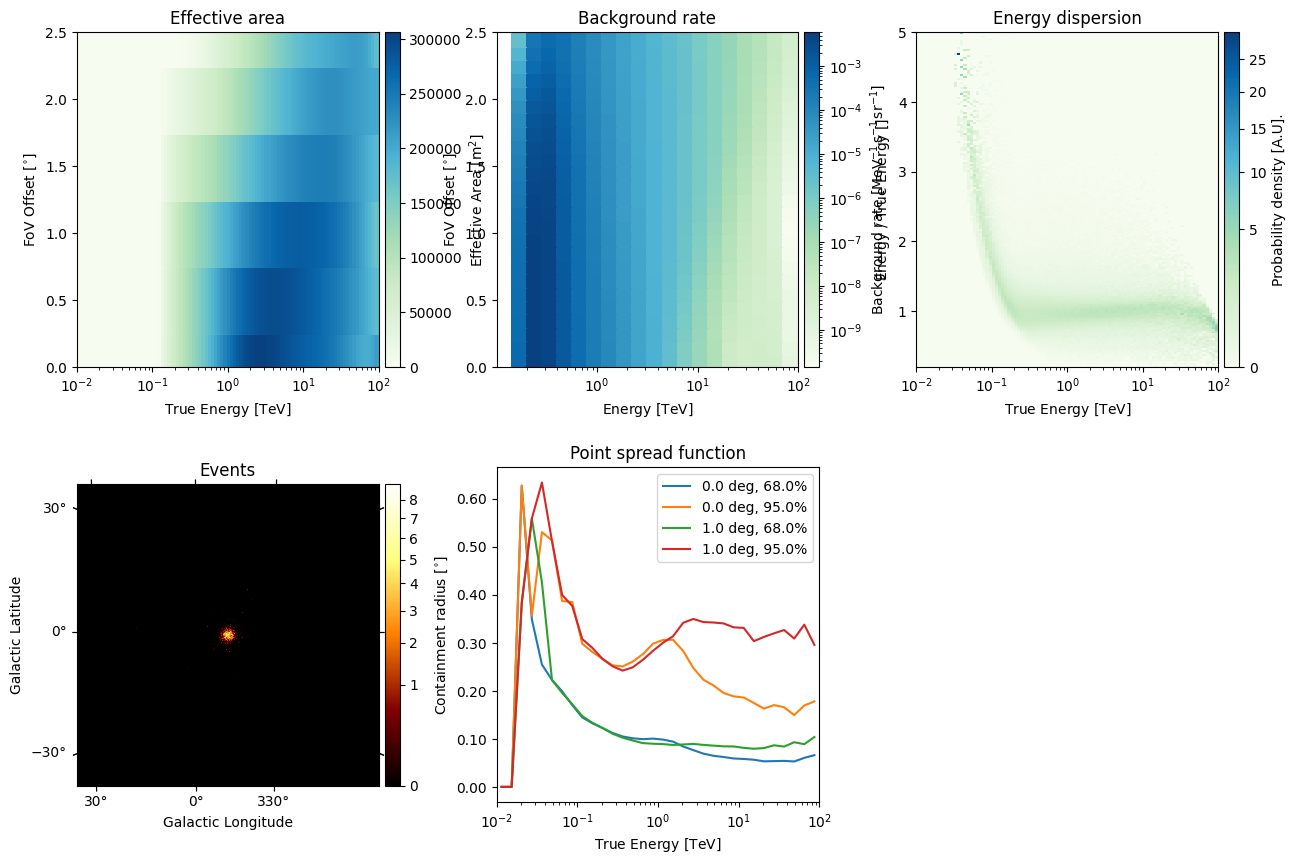

In [12]:
observations[0].peek()

# Preparing reduced datasets geometry

We define a reference geometry for our analysis.

We choose a WCS based geometry. We define the center of the geometry by our target source, assign a binsize of 0.02 deg, the width of the geometry, and also define an energy axis.

This geometry will be what our final dataset will look like.

In [74]:
energy_axis = MapAxis.from_energy_bounds(0.1, 10.0, 15, unit="TeV")

geom = WcsGeom.create(
    skydir=target_position,
    binsz=0.02,
    width=(6, 6),
    frame="galactic",
    axes=[energy_axis],
)

Important: we have both a 'true' energy axis and 'reconstructed' energy axis. We must ensure that the true axis is both wider in energy and contains more bins than the 'reco'.

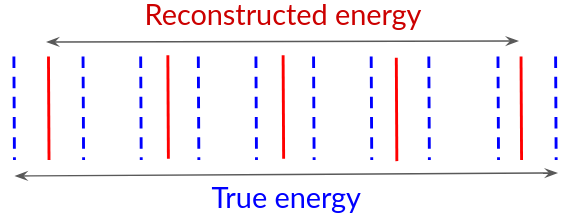

### Define the true energy axis based on the above information

In [75]:
energy_axis_true = MapAxis.from_energy_bounds(0.1*0.1, 1.5*10.0, 2*15, unit="TeV", name="energy_true")
energy_axis_true.edges

<Quantity [1.00000000e-02, 1.27605593e-02, 1.62831873e-02, 2.07782576e-02,
           2.65142187e-02, 3.38336259e-02, 4.31735988e-02, 5.50919266e-02,
           7.03003794e-02, 8.97072158e-02, 1.14471424e-01, 1.46071939e-01,
           1.86395964e-01, 2.37851674e-01, 3.03512038e-01, 3.87298335e-01,
           4.94214335e-01, 6.30645131e-01, 8.04738456e-01, 1.02689128e+00,
           1.31037070e+00, 1.67210629e+00, 2.13370114e+00, 2.72272199e+00,
           3.47434553e+00, 4.43345920e+00, 5.65734188e+00, 7.21908463e+00,
           9.21195572e+00, 1.17549707e+01, 1.50000000e+01] TeV>

In [18]:
print(geom)

WcsGeom

	axes       : ['lon', 'lat', 'energy']
	shape      : (300, 300, 15)
	ndim       : 3
	frame      : galactic
	projection : CAR
	center     : 347.3 deg, -0.3 deg
	width      : 6.0 deg x 6.0 deg
	wcs ref    : 347.3 deg, -0.3 deg




# Data reduction - FoV background method!

Create the maker classes to be used

The `~gammapy.datasets.MapDatasetMaker` object is initialized as well as the `~gammapy.makers.SafeMaskMaker` that carries here a maximum offset selection.


In [76]:
stacked = MapDataset.create(
    geom=geom, energy_axis_true=energy_axis_true, name="rxj-stacked"
)

We need to mask out any sources with significant emission.

You can check the http://gamma-sky.net to see if there are sources in the FoV and create an exclusion region based that.

In [22]:
circle = CircleSkyRegion(target_position, 0.7*u.deg)
regions = [circle]
exclusion_mask = ~geom.region_mask(regions=regions)

## Try to plot the exclusion mask

In [23]:
exclusion_mask.plot_interactive()

interactive(children=(SelectionSlider(continuous_update=False, description='Select energy:', layout=Layout(wid…

Create the `makers`.

In [77]:
maker = MapDatasetMaker(
    selection=["counts", "background", "psf", "edisp", "exposure"]
)
safe_mask_maker = SafeMaskMaker(
    methods=["offset-max", "aeff-max", "bkg-peak"], offset_max="2.3 deg"
)
fov_bkg_maker = FoVBackgroundMaker(method="fit", exclusion_mask=exclusion_mask)

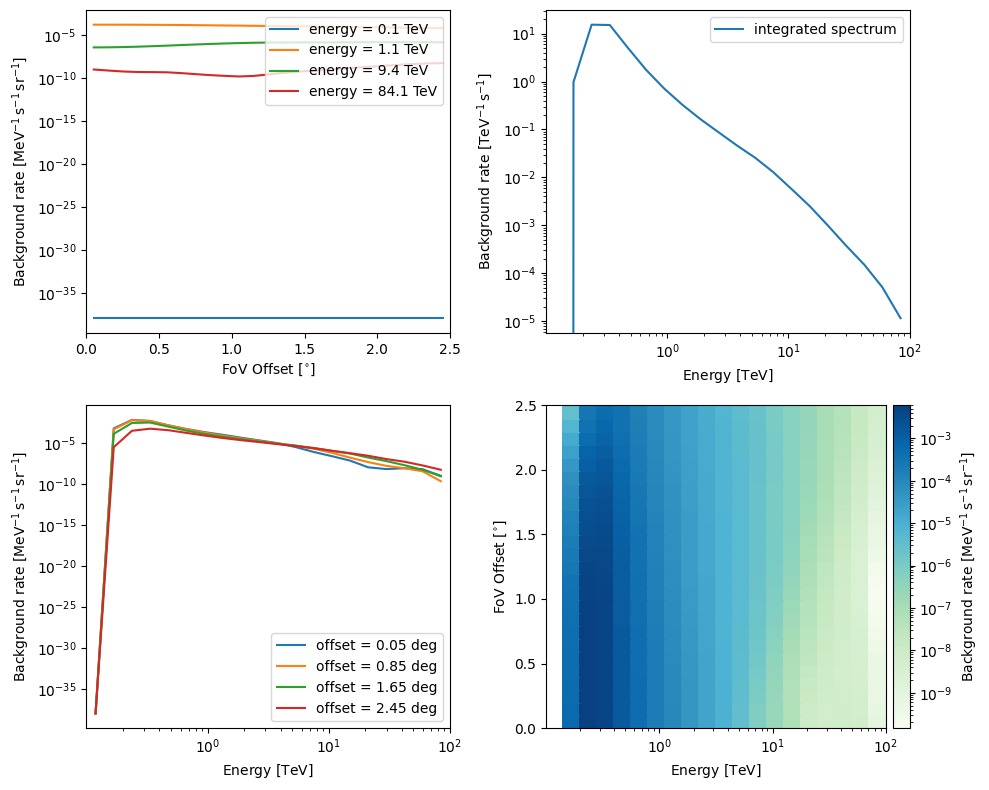

In [24]:
observations[0].bkg.peek()

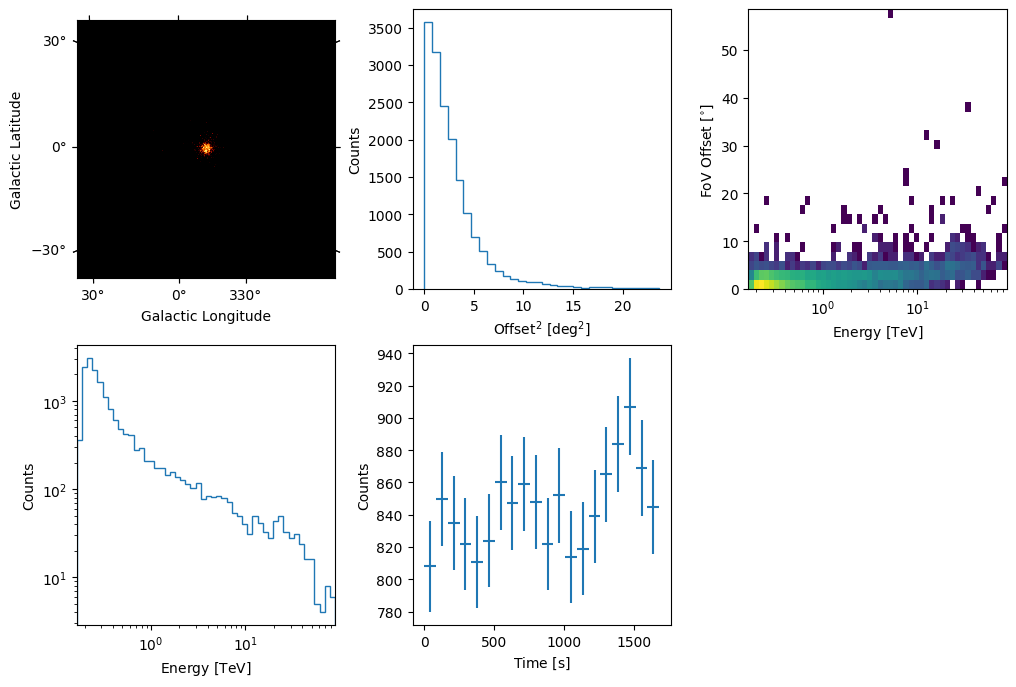

In [25]:
observations[0].events.peek()

### Perform the data reduction loop recalling the order:
- maker
- safe mask
- FoVbkg

In [78]:
for obs in observations:
    dataset = maker.run(stacked.cutout(target_position, 6*u.deg), obs)
    dataset = safe_mask_maker.run(dataset, obs)
    dataset = fov_bkg_maker.run(dataset, obs)
    print(
        f"Background norm obs {obs.obs_id}: {dataset.background_model.spectral_model.norm.value:.2f}"
    )
    stacked.stack(dataset)

Background norm obs 20326: 0.99
Background norm obs 20327: 1.02
Background norm obs 20349: 0.96
Background norm obs 20350: 1.01
Background norm obs 20396: 0.99
Background norm obs 20397: 1.02
Background norm obs 20421: 1.02
Background norm obs 20422: 0.97
Background norm obs 20517: 0.97
Background norm obs 20518: 0.94
Background norm obs 20519: 0.97
Background norm obs 20521: 0.94
Background norm obs 20898: 0.98
Background norm obs 20899: 0.97
Background norm obs 20900: 0.94


array([[<WCSAxes: title={'center': 'Energy 100 GeV - 136 GeV'}>,
        <WCSAxes: title={'center': 'Energy 136 GeV - 185 GeV'}>,
        <WCSAxes: title={'center': 'Energy 185 GeV - 251 GeV'}>],
       [<WCSAxes: title={'center': 'Energy 251 GeV - 341 GeV'}>,
        <WCSAxes: title={'center': 'Energy 341 GeV - 464 GeV'}>,
        <WCSAxes: title={'center': 'Energy 464 GeV - 631 GeV'}>],
       [<WCSAxes: title={'center': 'Energy 631 GeV - 858 GeV'}>,
        <WCSAxes: title={'center': 'Energy 858 GeV - 1.17 TeV'}>,
        <WCSAxes: title={'center': 'Energy 1.17 TeV - 1.58 TeV'}>],
       [<WCSAxes: title={'center': 'Energy 1.58 TeV - 2.15 TeV'}>,
        <WCSAxes: title={'center': 'Energy 2.15 TeV - 2.93 TeV'}>,
        <WCSAxes: title={'center': 'Energy 2.93 TeV - 3.98 TeV'}>],
       [<WCSAxes: title={'center': 'Energy 3.98 TeV - 5.41 TeV'}>,
        <WCSAxes: title={'center': 'Energy 5.41 TeV - 7.36 TeV'}>,
        <WCSAxes: title={'center': 'Energy 7.36 TeV - 10.0 TeV'}>]],
    

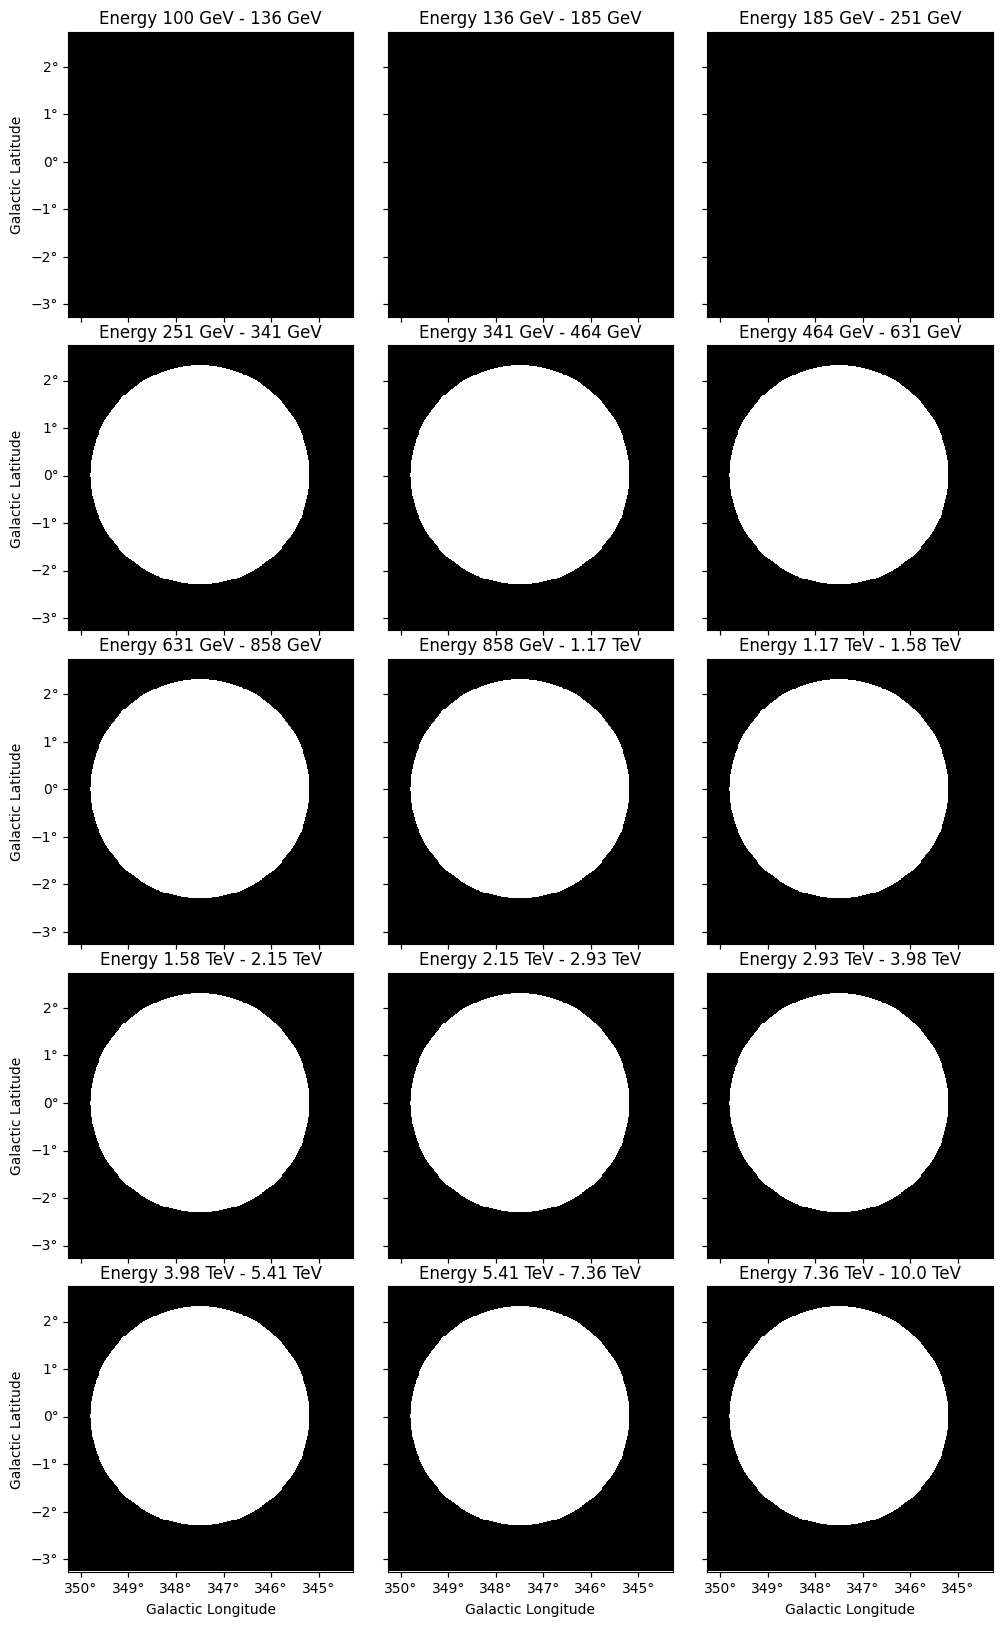

In [79]:
dataset.mask_safe.plot_grid()

array([[<WCSAxes: title={'center': 'Energy 300 GeV - 379 GeV'}>,
        <WCSAxes: title={'center': 'Energy 379 GeV - 479 GeV'}>,
        <WCSAxes: title={'center': 'Energy 479 GeV - 605 GeV'}>],
       [<WCSAxes: title={'center': 'Energy 605 GeV - 764 GeV'}>,
        <WCSAxes: title={'center': 'Energy 764 GeV - 965 GeV'}>,
        <WCSAxes: title={'center': 'Energy 965 GeV - 1.22 TeV'}>],
       [<WCSAxes: title={'center': 'Energy 1.22 TeV - 1.54 TeV'}>,
        <WCSAxes: title={'center': 'Energy 1.54 TeV - 1.95 TeV'}>,
        <WCSAxes: title={'center': 'Energy 1.95 TeV - 2.46 TeV'}>],
       [<WCSAxes: title={'center': 'Energy 2.46 TeV - 3.11 TeV'}>,
        <WCSAxes: title={'center': 'Energy 3.11 TeV - 3.93 TeV'}>,
        <WCSAxes: title={'center': 'Energy 3.93 TeV - 4.96 TeV'}>],
       [<WCSAxes: title={'center': 'Energy 4.96 TeV - 6.27 TeV'}>,
        <WCSAxes: title={'center': 'Energy 6.27 TeV - 7.92 TeV'}>,
        <WCSAxes: title={'center': 'Energy 7.92 TeV - 10.0 TeV'}>]],


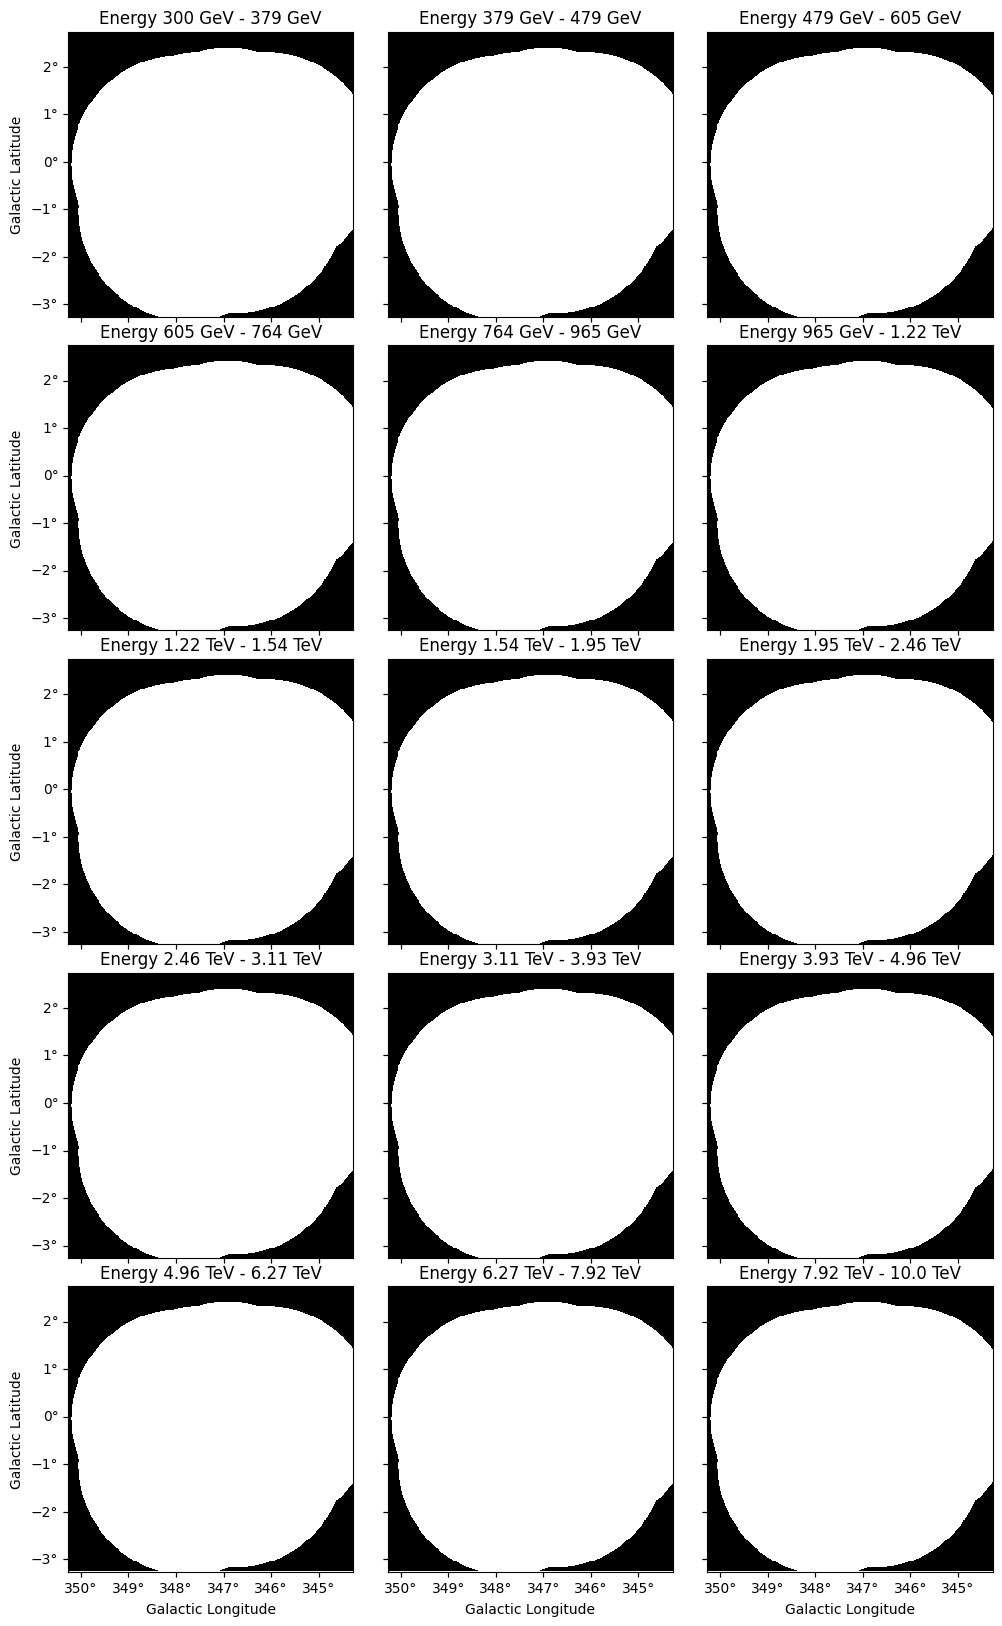

In [72]:
stacked.mask_safe.plot_grid()

In [31]:
print(stacked)

MapDataset
----------

  Name                            : rxj-stacked 

  Total counts                    : 94069 
  Total background counts         : 91526.87
  Total excess counts             : 2542.13

  Predicted counts                : 91526.87
  Predicted background counts     : 91526.87
  Predicted excess counts         : nan

  Exposure min                    : 3.97e+05 m2 s
  Exposure max                    : 8.17e+09 m2 s

  Number of total bins            : 1350000 
  Number of fit bins              : 1058670 

  Fit statistic type              : cash
  Fit statistic value (-2 log(L)) : nan

  Number of models                : 0 
  Number of parameters            : 0
  Number of free parameters       : 0




We can save this file so that later you can manipulate it!

In [33]:
stacked.write("stacked_MapDataset.fits", overwrite=True)

We can also `peek` this, just like we did with the observations.

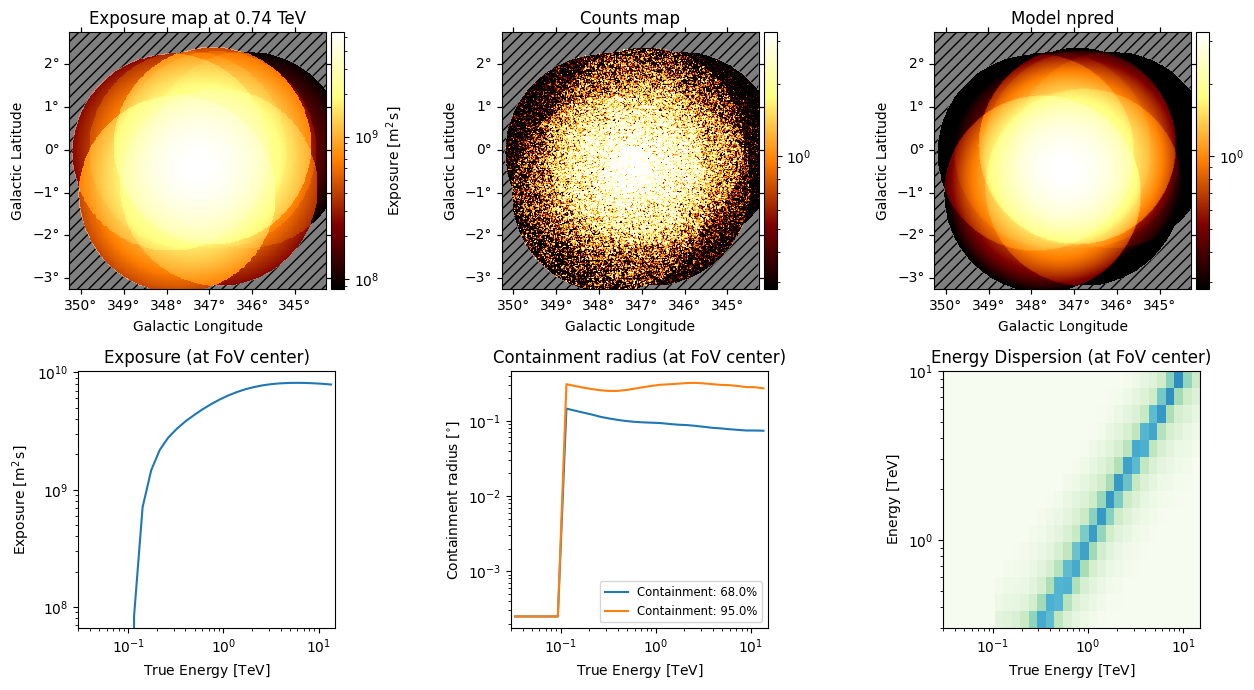

In [34]:
stacked.peek()

It looks like we have some source based on the counts image but it is hard to discern. This is because we have a map with very fine binning, so to view this better we can plot (for example) a counts map which has been smoothed.

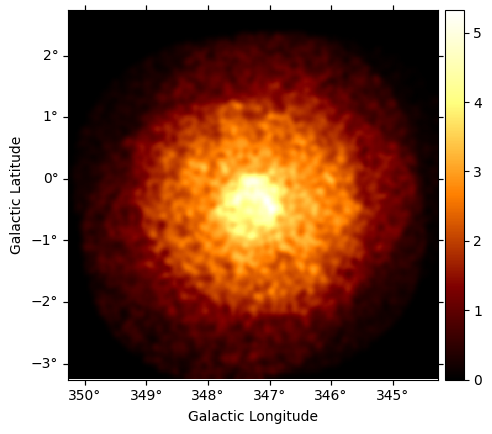

In [35]:
stacked.counts.reduce_over_axes().smooth(0.05 * u.deg).plot(add_cbar=True)
plt.show()

Note: in the about plot I utilised the `reduce_over_axes` functionality. If you print the shape of the `counts` object, you will see that we have a third axis in energy which has the same amount of bins as we first defined for our `geom`. This function will reduce the non-spatial axes of the map (i.e. the energy axis), such that it just has 1 bin and can be plotted as a 2D figure with the `plot` functionality.



## Compute an excess and a significance map

In [36]:
estimator = ExcessMapEstimator(
    0.1 * u.deg, selection_optional=[], energy_edges=[0.4, 20] * u.TeV
)
maps = estimator.run(stacked)

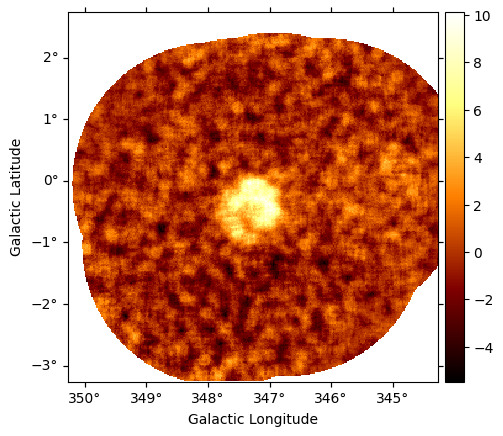

In [37]:
maps.sqrt_ts.plot(add_cbar=True)
plt.show()

### We can plot the excess and significance maps

<WCSAxes: title={'center': 'Excess map'}>

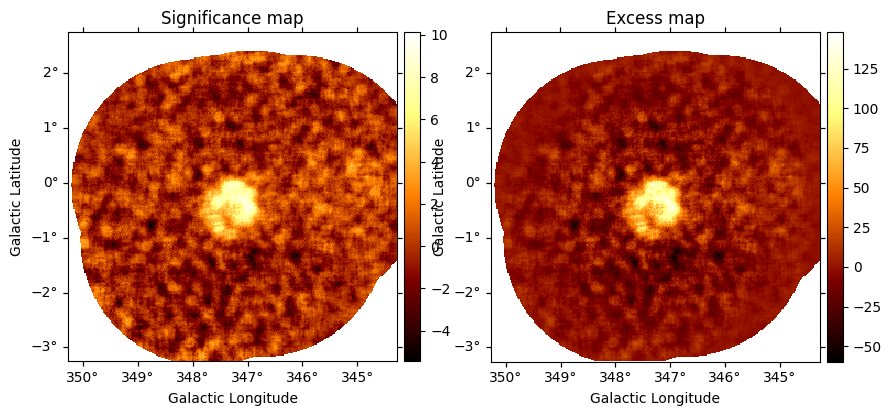

In [38]:
plt.figure(figsize=(10, 10))
ax1 = plt.subplot(221, projection=maps.sqrt_ts.geom.wcs)
ax2 = plt.subplot(222, projection=maps.sqrt_ts.geom.wcs)

ax1.set_title("Significance map")
maps.sqrt_ts.plot(ax=ax1, add_cbar=True)

ax2.set_title("Excess map")
maps.npred_excess.plot(ax=ax2, add_cbar=True)

# Can you create a map for the flux now?

Recall: it is possible to have autocompletion suggestions. Try it yourself with writing `maps.` and then press crtl+space

<WCSAxes: >

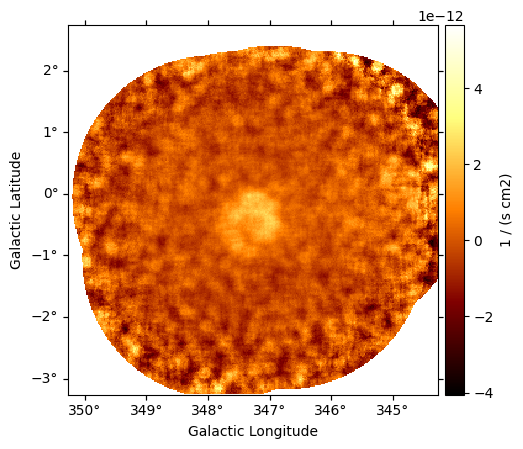

In [39]:
maps.flux.plot( add_cbar=True)

# What about a map in different energy bins?

In [40]:
energy_edges = [0.3, 1, 4, 10] * u.TeV
estimator = ExcessMapEstimator(
    0.1 * u.deg, selection_optional=[], energy_edges=energy_edges
)
maps = estimator.run(stacked)

array([<WCSAxes: title={'center': 'Energy 300 GeV - 965 GeV'}>,
       <WCSAxes: title={'center': 'Energy 965 GeV - 3.93 TeV'}>,
       <WCSAxes: title={'center': 'Energy 3.93 TeV - 10.0 TeV'}>],
      dtype=object)

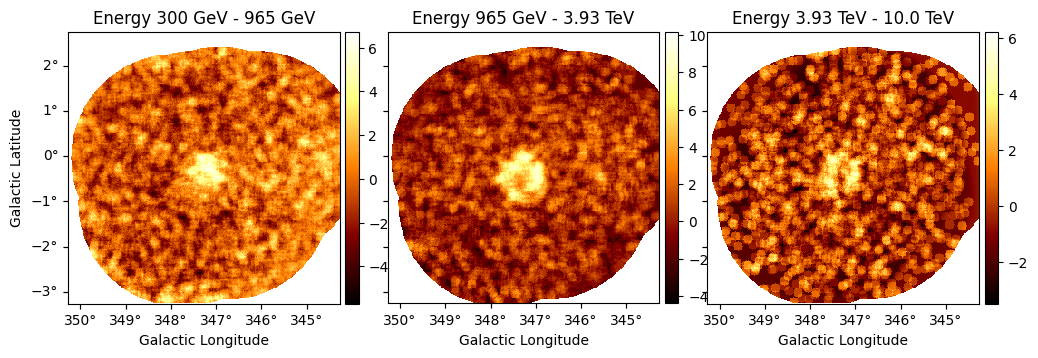

In [41]:
maps.sqrt_ts.plot_grid( add_cbar=True)

### Bonus: plot the exclusion mask on top of the image to ensure we excluded all significant emission from the background when we created the dataset

The exclusion mask was created based off a `region` so we can utilise its functionality to plot it. 

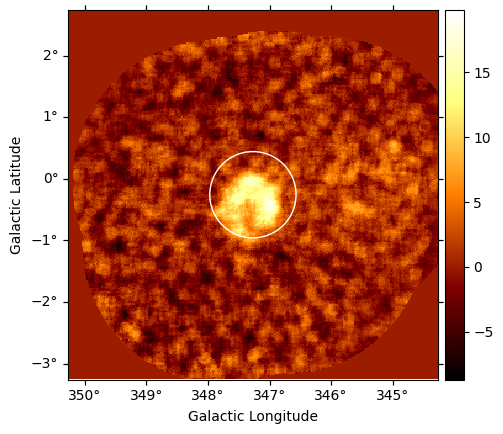

In [42]:
skymap = maps.sqrt_ts.reduce_over_axes()

ax = skymap.plot(add_cbar=True)
circle.to_pixel(ax.wcs).plot(ax=ax, color="white")
plt.show()

### Well done!! You have gone from DL3 data products to a DL4 dataset, which can be used for SCIENCE! 🥳


## Lets do some science!

# Exercises: 3D modeling - fit a model to our dataset


The 3D analysis consists of a simultaneous fit of the spectral and spatial parameters of one or multiple sources. Here, we focus only on a single source, centered at the coordinates l=347.269°, b=-0.257°. To perform the fit, we firstly need to define a model: we can try with a Gaussian morphology and a powerlaw spectral shape.

You can utilise the 'tab' completion on the following cell to see which model are available to use. Note: they are named according to their type so you can guess what the 'Gaussian' morphology model should be called.

In [43]:
from gammapy.modeling.models import GaussianSpatialModel, PowerLawSpectralModel
GaussianSpatialModel?

Init signature: GaussianSpatialModel(**kwargs)
Docstring:     
Two-dimensional Gaussian model.

For more information see :ref:`gaussian-spatial-model`.

Parameters
----------
lon_0, lat_0 : `~astropy.coordinates.Angle`
    Center position.
    Default is "0 deg", "0 deg".
sigma : `~astropy.coordinates.Angle`
    Length of the major semiaxis of the Gaussian, in angular units.
    Default is 1 deg.
e : `float`
    Eccentricity of the Gaussian (:math:`0<= e<= 1`).
    Default is 0.
phi : `~astropy.coordinates.Angle`
    Rotation angle :math:`\phi`: of the major semiaxis (:math:`-180 <= phi <= 180`).
    Increases counter-clockwise from the North direction.
    Default is 0 deg.
frame : {"icrs", "galactic"}
    Center position coordinate frame.
File:           ~/Prog/gammapy/gammapy_dev/gammapy/modeling/models/spatial.py
Type:           type
Subclasses:     

In [47]:
spatial_model = GaussianSpatialModel(lon_0=target_position.l,lat_0= target_position.b, sigma=0.4*u.deg, e=0, phi=0*u.deg, frame="galactic")

### 1 - Show on the map that this is a suitable guess for the emission extension and position

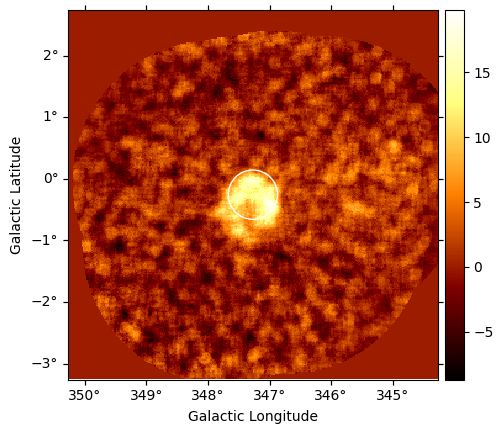

In [49]:
skymap = maps.sqrt_ts.reduce_over_axes()

ax = skymap.plot(add_cbar=True)
spatial_model.to_region().to_pixel(ax.wcs).plot(ax=ax, color="white")
plt.show()

### 2 - Create a spectral model, use a simple PowerLaw here. 

In [50]:
PowerLawSpectralModel?

Init signature: PowerLawSpectralModel(**kwargs)
Docstring:     
Spectral power-law model.

For more information see :ref:`powerlaw-spectral-model`.

Parameters
----------
index : `~astropy.units.Quantity`
    :math:`\Gamma`.
    Default is 2.0.
amplitude : `~astropy.units.Quantity`
    :math:`\phi_0`.
    Default is 1e-12 cm-2 s-1 TeV-1.
reference : `~astropy.units.Quantity`
    :math:`E_0`.
    Default is 1 TeV.

See Also
--------
PowerLaw2SpectralModel, PowerLawNormSpectralModel
File:           ~/Prog/gammapy/gammapy_dev/gammapy/modeling/models/spectral.py
Type:           type
Subclasses:     

In [52]:
spectral_model = PowerLawSpectralModel(index=2, amplitude= 1e-11* u.Unit("cm-2 s-1 TeV-1"), reference=1*u.TeV)

We limit the model position inside a 1 deg box centered on the reference position of RX J1713

In [53]:
spatial_model.lon_0.min = spatial_model.lon_0.value - 0.5
spatial_model.lon_0.max = spatial_model.lon_0.value + 0.5

### 3 - Limit the `lat_0` values yourself

In [54]:
spatial_model.lat_0.min = spatial_model.lat_0.value - 0.5
spatial_model.lat_0.max = spatial_model.lat_0.value + 0.5

In [55]:
from gammapy.modeling.models import SkyModel, FoVBackgroundModel, Models

In [56]:
sky_model = SkyModel(
    spectral_model=spectral_model, spatial_model=spatial_model, name="rxj"
)

Now, we define a global ~gammapy.modeling.model.FoVBackgroundModel in order to finely adjust the level of residual CR backgroud. This should not be forgotten.

Note: we assume the background is well know and can be taken from the IRF bkg model


In [57]:
bkg_model = FoVBackgroundModel(dataset_name=stacked.name)

Now we assign these models to our reduced dataset:

In [58]:
stacked.models = Models([sky_model, bkg_model])

### 4 - Look at your stacked dataset. It should now contain information on the models we just applied

In [59]:
stacked

### 5 - Fit the model

The `~gammapy.modeling.Fit` class is orchestrating the fit, connecting the `stats` method of the dataset to the minimizer. By default, it uses `iminuit`.

Its constructor takes a list of dataset as argument.

In [61]:
from gammapy.modeling import Fit
Fit?

Init signature:
Fit(
    backend='minuit',
    optimize_opts=None,
    covariance_opts=None,
    confidence_opts=None,
    store_trace=False,
)
Docstring:     
Fit class.

The fit class provides a uniform interface to multiple fitting backends.
Currently available: "minuit", "sherpa" and "scipy".

Parameters
----------
backend : {"minuit", "scipy" "sherpa"}
    Global backend used for fitting. Default is "minuit".
optimize_opts : dict
    Keyword arguments passed to the optimizer. For the `"minuit"` backend
    see https://iminuit.readthedocs.io/en/stable/reference.html#iminuit.Minuit
    for a detailed description of the available options. If there is an entry
    'migrad_opts', those options will be passed to `iminuit.Minuit.migrad()`.

    For the `"sherpa"` backend you can from the options:

        * `"simplex"`
        * `"levmar"`
        * `"moncar"`
        * `"gridsearch"`

    Those methods are described and compared in detail on
    http://cxc.cfa.harvard.edu/sherpa/methods

In [62]:
Fit.run?

Signature: Fit.run(self, datasets)
Docstring:
Run all fitting steps.

Parameters
----------
datasets : `Datasets` or list of `Dataset`
    Datasets to optimize.

Returns
-------
fit_result : `FitResult`
    Fit result.
File:      ~/Prog/gammapy/gammapy_dev/gammapy/modeling/fit.py
Type:      function

In [63]:
fit = Fit()
result = fit.run([stacked])

### Inspecting residuals

For any fit it is useful to inspect the residual images. We have a few options on the dataset object to handle this. First we can use `.plot_residuals_spatial()` to plot a residual image, summed over all energies:

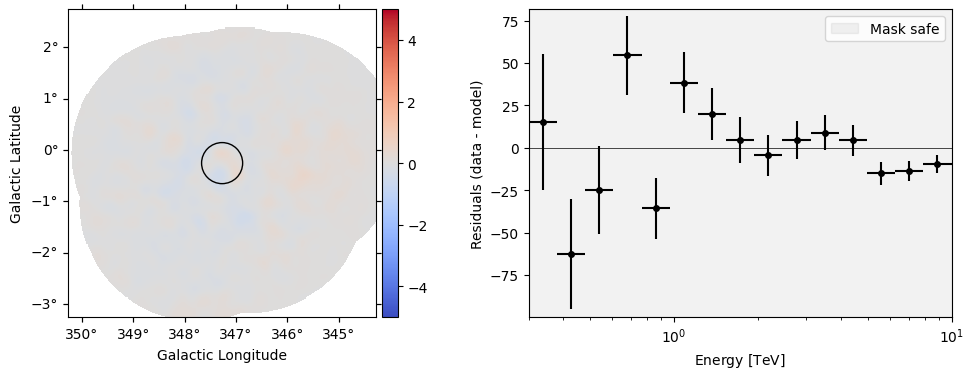

In [64]:
region = CircleSkyRegion(center=target_position, radius=0.4 * u.deg)
stacked.plot_residuals(kwargs_spectral={"region": region});

### 6 - Plot the fitted spectrum

Making a butterfly plot

The SpectralModel component can be used to produce a, so-called, butterfly plot showing the envelope of the model taking into account parameter uncertainties:


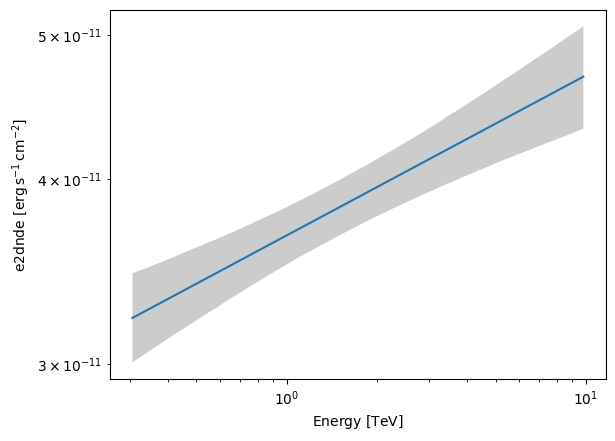

In [66]:
spec = sky_model.spectral_model

energy_bounds = [0.3, 10] *u.TeV #energy_axis.bounds
spec.plot(energy_bounds=energy_bounds, sed_type="e2dnde")
ax = spec.plot_error(energy_bounds=energy_bounds, sed_type="e2dnde")

### 7 - Computing flux points

We can now compute some flux points using the ~gammapy.estimators.FluxPointsEstimator.

Besides the list of datasets to use, we must provide it the energy intervals on which to compute flux points as well as the model component name.


In [67]:
from gammapy.estimators import FluxPointsEstimator
FluxPointsEstimator?

Init signature:
FluxPointsEstimator(
    energy_edges=<Quantity [ 1., 10.] TeV>,
    sum_over_energy_groups=False,
    n_jobs=None,
    parallel_backend=None,
    allow_multiple_telescopes=False,
    **kwargs,
)
Docstring:     
Flux points estimator.

Estimates flux points for a given list of datasets, energies and spectral model.

To estimate the flux point the amplitude of the reference spectral model is
fitted within the energy range defined by the energy group. This is done for
each group independently. The amplitude is re-normalized using the "norm" parameter,
which specifies the deviation of the flux from the reference model in this
energy group. See https://gamma-astro-data-formats.readthedocs.io/en/latest/spectra/binned_likelihoods/index.html
for details.

The method is also described in the `Fermi-LAT catalog paper <https://ui.adsabs.harvard.edu/abs/2015ApJS..218...23A>`__
or the `H.E.S.S. Galactic Plane Survey paper <https://ui.adsabs.harvard.edu/abs/2018A%26A...612A...1H>`__

<Quantity [ 0.3       ,  0.60491869,  1.21975541,  2.45950949,  4.9593442 ,
           10.        ] TeV>

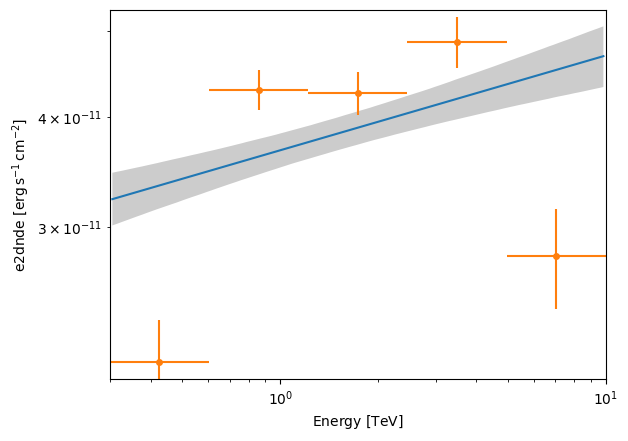

In [71]:
energy_edges= energy_axis.edges[::3]
fpe = FluxPointsEstimator(energy_edges=energy_edges, source="rxj")
flux_points = fpe.run(datasets=[stacked])

spec = sky_model.spectral_model

energy_bounds = [0.3, 10] *u.TeV #energy_axis.bounds
spec.plot(energy_bounds=energy_bounds, sed_type="e2dnde")
ax = spec.plot_error(energy_bounds=energy_bounds, sed_type="e2dnde")
flux_points.plot(ax=ax, sed_type="e2dnde")
plt.show()

## More advanced 

### 8 - Source significance

What is the TS-based significance of this source? You can estimate it by comparing the model likelihood without (null hypothesis) and with the source model

### 9 - Does the source exhibit energy-dependent morphology? 

A dedicated estimator has been implemented to answer to this question, EnergyDependentMorphologyEstimator